![tower_bridge](tower_bridge.jpeg)

As the climate changes, predicting the weather becomes ever more important for businesses. Since the weather depends on a lot of different factors, you will want to run a lot of experiments to determine what the best approach is to predict the weather. In this project, you will run experiments for different regression models predicting the mean temperature, using a combination of `sklearn` and `MLflow`.

You will be working with data stored in `london_weather.csv`, which contains the following columns:
- **date** - recorded date of measurement - (**int**)
- **cloud_cover** - cloud cover measurement in oktas - (**float**)
- **sunshine** - sunshine measurement in hours (hrs) - (**float**)
- **global_radiation** - irradiance measurement in Watt per square meter (W/m2) - (**float**)
- **max_temp** - maximum temperature recorded in degrees Celsius (°C) - (**float**)
- **mean_temp** - mean temperature in degrees Celsius (°C) - (**float**)
- **min_temp** - minimum temperature recorded in degrees Celsius (°C) - (**float**)
- **precipitation** - precipitation measurement in millimeters (mm) - (**float**)
- **pressure** - pressure measurement in Pascals (Pa) - (**float**)
- **snow_depth** - snow depth measurement in centimeters (cm) - (**float**)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15341 entries, 0 to 15340
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              15341 non-null  int64  
 1   cloud_cover       15322 non-null  float64
 2   sunshine          15341 non-null  float64
 3   global_radiation  15322 non-null  float64
 4   max_temp          15335 non-null  float64
 5   mean_temp         15305 non-null  float64
 6   min_temp          15339 non-null  float64
 7   precipitation     15335 non-null  float64
 8   pressure          15337 non-null  float64
 9   snow_depth        13900 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 1.2 MB
None


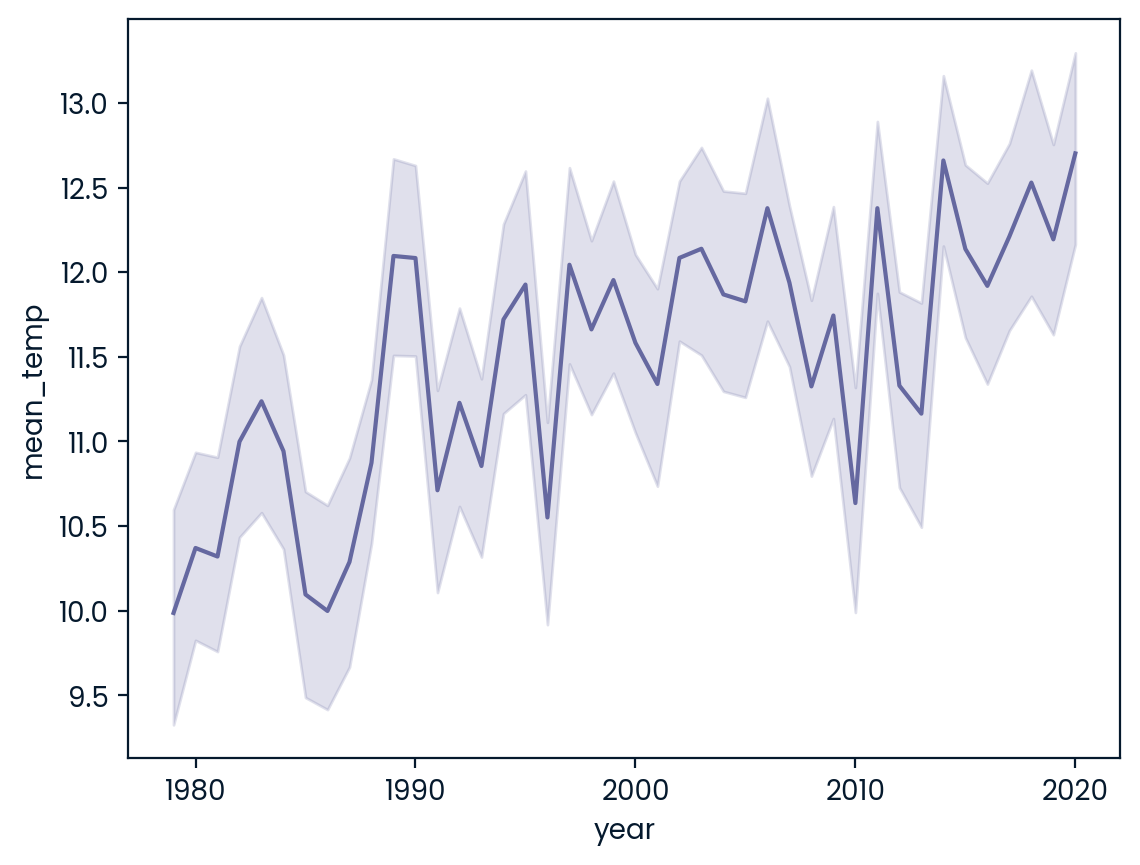

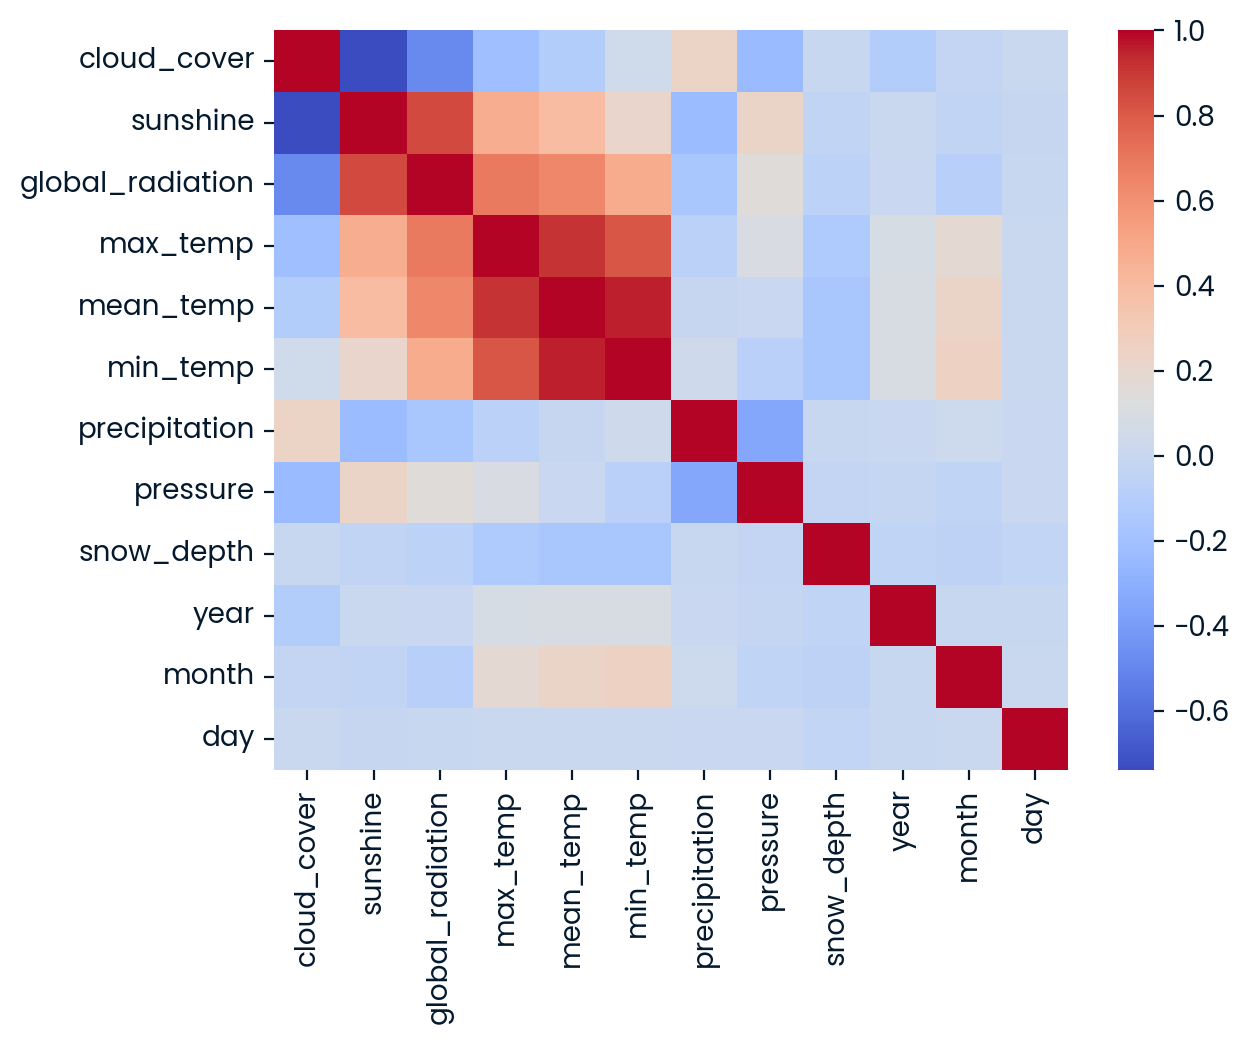

2026/11/12 10:05:51 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpdsctc4vw/model/model.pkl, flavor: sklearn), fall back to return ['scikit-learn==1.2.2', 'cloudpickle==2.1.0']. Set logging level to DEBUG to see the full traceback.
2026/11/12 10:05:52 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmp_1equwqr/model/model.pkl, flavor: sklearn), fall back to return ['scikit-learn==1.2.2', 'cloudpickle==2.1.0']. Set logging level to DEBUG to see the full traceback.


KeyboardInterrupt: 

In [5]:
# Run this cell to import the modules you require
import pandas as pd
import numpy as np
import mlflow
import mlflow.sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Read in the data
weather = pd.read_csv("london_weather.csv")
print(weather.info())

# Start coding here
# Use as many cells as you like

# Reading the data
# Determine the column names, data types, number of non-null values
# weather.head()
# weather.info()

# Data Cleaning
# Working with the date column, parse the date column as datetime type
weather['date'] = pd.to_datetime(weather['date'],format='%Y%m%d')

# Extract more data information (year, month, day)
weather['year'] = weather['date'].dt.year
weather['month'] = weather['date'].dt.month
weather['day'] = weather['date'].dt.day

# EDA
# Visualizing temperature
sns.lineplot(x="year", y="mean_temp", data=weather)
# sns.lineplot(x="month", y="mean_temp", data=weather)
plt.show()

# Compute the correlation matrix
corr_matrix = weather.corr()

# Display correlation matrix as heatmap
sns.heatmap(corr_matrix,cmap = 'coolwarm')
plt.show()

# Feature selection
# Filter significant columns
cols = ['global_radiation', 'sunshine', 'month', 'cloud_cover', 'snow_depth','mean_temp']
filtered_df = weather[cols]

# Remove rows with missing target values
filtered_df = filtered_df.dropna(subset=['mean_temp'])


# Preprocess data
# Imputing and normalizing data

# Check for features missing values
filtered_df.isna().sum() # snow_depth (mean), global_radiation (median), cloud_cover (median) contains missing values

# Separate features and targets
X = filtered_df[['global_radiation', 'sunshine', 'month', 'cloud_cover', 'snow_depth']]
y = filtered_df['mean_temp']

# Split the data between train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Impute features missing values
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Normalize feature values
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ML training and evaluation

# Create a MLflow experiment
mlflow.set_experiment("Experiment")

# Launch runs for Decision Trees with different depth and log parameters adn metrics
for idx, depth in enumerate(range(1,10)):
    run_name = f"run_{idx}"
    
    with mlflow.start_run():
        model = DecisionTreeRegressor(max_depth=depth)
        model.fit(X_train,y_train)
        y_pred = model.predict(X_test)
        RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
        mlflow.log_param("model", "DecisionTree")
        mlflow.log_param("depth", depth)
        mlflow.log_metric("rmse", RMSE)
        mlflow.sklearn.log_model(model, "model")

# Launch runs for Random Forests with different depth and log parameters adn metrics
for idx, depth in enumerate(range(1,10)):
    run_name = f"run_{idx}"
    
    with mlflow.start_run():
        model = RandomForestRegressor(max_depth=depth)
        model.fit(X_train,y_train)
        y_pred = model.predict(X_test)
        RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
        mlflow.log_param("model", "Randomforest")
        mlflow.log_param("depth", depth)
        mlflow.log_metric("rmse", RMSE)
        mlflow.sklearn.log_model(model, "model")

# Launch a run for a Linear regression log parameters adn metrics
with mlflow.start_run():
    lr = LinearRegression()
    lr.fit(X_train,y_train)
    y_pred = lr.predict(X_test)
    RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
    mlflow.log_param("model", "LinearRegression")
    mlflow.log_metric("rmse", RMSE)
    mlflow.sklearn.log_model(model, "model")
        

# Store experiment results
experiment_results = mlflow.search_runs()